<a href="https://colab.research.google.com/github/silvinalucerobcn-spec/el-techno-no-tiene-edad/blob/main/EDA_Techno_No_Tiene_Edad.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# El techno no tiene edad
## Análisis exploratorio de la escucha de música electrónica y techno en España (2010–2025)

### Motivación
Mi interés por este tema surge de mi afición al techno y de observar la presencia de personas mayores de 40 años en las fiestas a las que asisto. Esta observación me llevó a investigar cómo varía la escucha de este género según la edad.

### Objetivo
Analizar la evolución de la escucha de la categoría «Electrónica, tecno» según los grupos de edad y el sexo, utilizando cinco ediciones de la Encuesta de Hábitos y Prácticas Culturales en España.

### Fuente de datos
Ministerio de Cultura, CULTURABase.
Ediciones: 2010–2011, 2014–2015, 2018–2019, 2021–2022 y 2024–2025.

### Alcance del análisis
Los datos estudian la escucha de música grabada, no la asistencia a fiestas o festivales. Además, la categoría agrupa electrónica y techno, sin distinguirlos.

Las edades están agrupadas en intervalos, por lo que no podemos aislar exactamente a las personas mayores de 40 años.

La pregunta sobre géneros musicales admite respuestas múltiples: una persona puede seleccionar varios géneros y sus porcentajes no tienen que sumar 100 %.

In [23]:
# Importamos pandas para leer los archivos CSV y trabajar con sus datos.
# Usamos el nombre corto "pd" para llamar a sus funciones.
import pandas as pd

# Importamos pyplot, de matplotlib, para crear los gráficos del análisis.
# Usamos el nombre corto "plt" para llamar a sus funciones.
import matplotlib.pyplot as plt

In [24]:
# Leemos el archivo de la encuesta de 2024–2025.
# sep=";" indica que las columnas se separan con punto y coma.
# encoding="cp1252" permite leer las tildes y la ñ.
# decimal="," indica que los números utilizan coma decimal.
datos_2024 = pd.read_csv(
    "/content/musica2.csv",
    sep=";",
    encoding="cp1252",
    decimal=","
)

# Mostramos las primeras cinco filas para comprobar la lectura.
datos_2024.head()

,Sexo y edad,Género musical,periodo,Total
0,TOTAL,Total suelen escuchar en un trimestre,2024-2025,100.0
1,TOTAL,Canción infantil,2024-2025,8.9
2,TOTAL,Canción de autor,2024-2025,26.3
3,TOTAL,Canción melódica,2024-2025,24.1
4,TOTAL,Flamenco,2024-2025,21.2


In [25]:
# Cargamos la edición de 2010–2011.
# thousands="." indica que el punto separa los miles.
datos_2010 = pd.read_csv(
    "/content/musica04.csv",
    sep=";", encoding="cp1252", decimal=",", thousands="."
)

# Cargamos la edición de 2014–2015.
datos_2014 = pd.read_csv(
    "/content/musica00.csv",
    sep=";", encoding="cp1252", decimal=",", thousands="."
)

# Cargamos la edición de 2018–2019.
datos_2018 = pd.read_csv(
    "/content/musica01.csv",
    sep=";", encoding="cp1252", decimal=",", thousands="."
)

# Cargamos la edición de 2021–2022.
datos_2021 = pd.read_csv(
    "/content/musica3.csv",
    sep=";", encoding="cp1252", decimal=","
)

# Comprobamos las dimensiones de las cinco tablas.
# shape devuelve dos números: (cantidad de filas, cantidad de columnas).
print("2010–2011:", datos_2010.shape)
print("2014–2015:", datos_2014.shape)
print("2018–2019:", datos_2018.shape)
print("2021–2022:", datos_2021.shape)
print("2024–2025:", datos_2024.shape)

2010–2011: (184, 3)
2014–2015: (184, 3)
2018–2019: (176, 4)
2021–2022: (176, 4)
2024–2025: (184, 4)


In [26]:
# info() muestra las columnas, los valores no vacíos y los tipos de datos.
# Revisamos cada edición antes de unirlas.

print("EDICIÓN 2010–2011")
datos_2010.info()

print("\nEDICIÓN 2014–2015")
datos_2014.info()

print("\nEDICIÓN 2018–2019")
datos_2018.info()

print("\nEDICIÓN 2021–2022")
datos_2021.info()

print("\nEDICIÓN 2024–2025")
datos_2024.info()

EDICIÓN 2010–2011
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 184 entries, 0 to 183
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Sexo y edad     184 non-null    object 
 1   Género musical  184 non-null    object 
 2   Total           184 non-null    float64
dtypes: float64(1), object(2)
memory usage: 4.4+ KB

EDICIÓN 2014–2015
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 184 entries, 0 to 183
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Sexo y edad     184 non-null    object 
 1   Género musical  184 non-null    object 
 2   Total           184 non-null    float64
dtypes: float64(1), object(2)
memory usage: 4.4+ KB

EDICIÓN 2018–2019
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 176 entries, 0 to 175
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          ------------

In [27]:
# Estos dos archivos no incluyen el periodo como columna.
# Lo añadimos usando la edición de la encuesta de la que procede cada archivo.
# El mismo periodo se asigna a todas las filas de cada tabla.

datos_2010["periodo"] = "2010-2011"
datos_2014["periodo"] = "2014-2015"

# Comprobamos cómo queda la primera tabla con la nueva columna.
datos_2010.head()

,Sexo y edad,Género musical,Total,periodo
0,TOTAL,Total suelen escuchar en un trimestre (Miles),32574.0,2010-2011
1,TOTAL,Canción infantil (%),4.6,2010-2011
2,TOTAL,Canción de autor (%),31.6,2010-2011
3,TOTAL,Canción melódica (%),33.9,2010-2011
4,TOTAL,Flamenco (%),21.5,2010-2011


In [28]:
# Unimos las cinco tablas en una sola.
# pandas empareja las columnas por su nombre, aunque estén en distinto orden.
# ignore_index=True crea una numeración continua para todas las filas.

datos = pd.concat(
    [datos_2010, datos_2014, datos_2018, datos_2021, datos_2024],
    ignore_index=True
)

# Comprobamos las dimensiones de la tabla reunida.
print("Filas y columnas:", datos.shape)

# Contamos cuántas filas hay de cada periodo.
print("\nFilas por periodo:")
print(datos["periodo"].value_counts().sort_index())

Filas y columnas: (904, 4)

Filas por periodo:
periodo
2010-2011    184
2014-2015    184
2018-2019    176
2021-2022    176
2024-2025    184
Name: count, dtype: int64


In [29]:
# isna() identifica los valores vacíos.
# sum() cuenta cuántos hay en cada columna.
print("Valores vacíos por columna:")
print(datos.isna().sum())

# duplicated() identifica filas completamente iguales.
# El periodo también se tiene en cuenta:
# dos filas de distintos periodos no son duplicadas.
print("\nFilas duplicadas:")
print(datos.duplicated().sum())

Valores vacíos por columna:
Sexo y edad       0
Género musical    0
Total             0
periodo           0
dtype: int64

Filas duplicadas:
0


In [30]:
# unique() muestra los valores distintos de una columna.
# Nos permite revisar las categorías antes de unificarlas.

print("Categorías de sexo y edad:")
print(datos["Sexo y edad"].unique())

print("\nCategorías de género musical:")
print(datos["Género musical"].unique())

Categorías de sexo y edad:
['TOTAL' 'Varones' 'Mujeres' 'De 15 a 24 años' 'De 25 a 34 años'
 'De 35 a 44 años' 'De 45 a 54 años' 'De 55 años y más' 'Hombres'
 'De 55 años en adelante']

Categorías de género musical:
['Total suelen escuchar en un trimestre (Miles)' 'Canción infantil (%)'
 'Canción de autor (%)' 'Canción melódica (%)' 'Flamenco (%)'
 'Nuevo flamenco (%)' 'Otro folklore español  (%)' 'Pop/ Rock español (%)'
 'Pop/ Rock latino (%)' 'Pop/ Rock extranjero (%)' 'Blues, Soul (%)'
 'Jazz (%)' 'World music, folk, étnica (%)' 'Reggae (%)'
 'Rap, Hip hop (%)' 'Electrónica, tecno (%)' 'Hard rock, metal, punk (%)'
 'Dance/ house (%)' 'Música clásica (%)' 'Lírica (%)' 'Ópera (%)'
 'Zarzuela (%)' 'Otros (%)' 'Total suelen escuchar en un trimestre'
 'Canción infantil' 'Canción de autor' 'Canción melódica' 'Flamenco'
 'Nuevo flamenco' 'Otro folklore español' 'Pop/ Rock español'
 'Pop/ Rock latino' 'Pop/ Rock extranjero' 'Blues, Soul' 'Jazz'
 'World music, folk, étnica' 'Reggae' 'Rap, Hi

In [31]:
# Creamos una copia para limpiar los datos conservando la tabla original.
datos_limpios = datos.copy()

# Unificamos dos etiquetas que representan los mismos grupos.
datos_limpios["Sexo y edad"] = datos_limpios["Sexo y edad"].replace({
    "Varones": "Hombres",
    "De 55 años y más": "De 55 años en adelante"
})

# Comprobamos que ahora solo aparecen los ocho grupos esperados.
print(datos_limpios["Sexo y edad"].unique())

['TOTAL' 'Hombres' 'Mujeres' 'De 15 a 24 años' 'De 25 a 34 años'
 'De 35 a 44 años' 'De 45 a 54 años' 'De 55 años en adelante']


In [32]:
# Quitamos el texto " (%)" de los nombres.
# regex=False indica que buscamos ese texto exacto.
datos_limpios["Género musical"] = (
    datos_limpios["Género musical"]
    .str.replace(" (%)", "", regex=False)
    .str.split()
    .str.join(" ")
)

# split() separa las palabras y join(" ") las reúne con un solo espacio.
# Así eliminamos espacios repetidos y espacios al principio o al final.

# Comprobamos los nombres resultantes.
print(datos_limpios["Género musical"].unique())

['Total suelen escuchar en un trimestre (Miles)' 'Canción infantil'
 'Canción de autor' 'Canción melódica' 'Flamenco' 'Nuevo flamenco'
 'Otro folklore español' 'Pop/ Rock español' 'Pop/ Rock latino'
 'Pop/ Rock extranjero' 'Blues, Soul' 'Jazz' 'World music, folk, étnica'
 'Reggae' 'Rap, Hip hop' 'Electrónica, tecno' 'Hard rock, metal, punk'
 'Dance/ house' 'Música clásica' 'Lírica' 'Ópera' 'Zarzuela' 'Otros'
 'Total suelen escuchar en un trimestre' 'Pop, Rock español'
 'Pop, Rock latino' 'Pop, Rock extranjero' 'Folk, étnica' 'Reggae, Ska'
 'Dance, house' 'Trap, Reggaetón']


In [33]:
# Identificamos las dos categorías que representan totales.
es_total = datos_limpios["Género musical"].isin([
    "Total suelen escuchar en un trimestre (Miles)",
    "Total suelen escuchar en un trimestre"
])

# Guardamos los totales en una tabla aparte.
datos_totales = datos_limpios.loc[es_total].copy()

# El símbolo ~ significa "lo contrario":
# seleccionamos las filas que NO son totales.
datos_porcentajes = datos_limpios.loc[~es_total].copy()

# Comprobamos cuántas filas quedan en cada tabla.
print("Filas de totales:", len(datos_totales))
print("Filas de porcentajes:", len(datos_porcentajes))

Filas de totales: 40
Filas de porcentajes: 864


In [34]:
# Seleccionamos únicamente las filas de la categoría "Electrónica, tecno".
# Conservamos todos los periodos y todos los grupos de sexo y edad.
datos_techno = datos_porcentajes.loc[
    datos_porcentajes["Género musical"] == "Electrónica, tecno"
].copy()

# Renombramos "Total" como "Porcentaje" para que su significado sea más claro.
datos_techno = datos_techno.rename(columns={"Total": "Porcentaje"})

# Comprobamos cuántas filas tenemos de cada periodo.
print("Filas por periodo:")
print(datos_techno["periodo"].value_counts().sort_index())

# Mostramos las primeras cinco filas.
display(datos_techno.head())

Filas por periodo:
periodo
2010-2011    8
2014-2015    8
2018-2019    8
2021-2022    8
2024-2025    8
Name: count, dtype: int64


,Sexo y edad,Género musical,Porcentaje,periodo
15,TOTAL,"Electrónica, tecno",9.1,2010-2011
38,Hombres,"Electrónica, tecno",12.1,2010-2011
61,Mujeres,"Electrónica, tecno",6.2,2010-2011
84,De 15 a 24 años,"Electrónica, tecno",23.2,2010-2011
107,De 25 a 34 años,"Electrónica, tecno",15.0,2010-2011


In [35]:
# Seleccionamos solo los grupos de edad.
# startswith("De ") identifica las etiquetas que comienzan por "De ".
# Así dejamos fuera TOTAL, Hombres y Mujeres.
techno_edades = datos_techno.loc[
    datos_techno["Sexo y edad"].str.startswith("De ")
].copy()

# Organizamos los porcentajes para facilitar la comparación:
# cada fila representa un grupo de edad y cada columna un periodo.
tabla_edades = techno_edades.pivot(
    index="Sexo y edad",
    columns="periodo",
    values="Porcentaje"
)

# Mostramos la tabla comparativa.
display(tabla_edades)

periodo,2010-2011,2014-2015,2018-2019,2021-2022,2024-2025
Sexo y edad,,,,,
De 15 a 24 años,23.2,28.5,30.2,25.7,28.6
De 25 a 34 años,15.0,17.5,22.6,23.4,29.5
De 35 a 44 años,7.3,9.9,14.9,16.5,20.7
De 45 a 54 años,4.6,5.4,9.6,9.5,15.9
De 55 años en adelante,1.1,1.6,3.6,4.0,6.5


In [36]:
# Restamos el porcentaje inicial al porcentaje final de cada grupo.
# La diferencia entre dos porcentajes se expresa en puntos porcentuales.
cambio_edades = (
    tabla_edades["2024-2025"] - tabla_edades["2010-2011"]
).round(1)

# Ordenamos los cambios de mayor a menor.
cambio_edades = cambio_edades.sort_values(ascending=False)

# Mostramos el resultado con un nombre descriptivo.
display(cambio_edades.to_frame(name="Cambio en puntos porcentuales"))

,Cambio en puntos porcentuales
Sexo y edad,
De 25 a 34 años,14.5
De 35 a 44 años,13.4
De 45 a 54 años,11.3
De 15 a 24 años,5.4
De 55 años en adelante,5.4


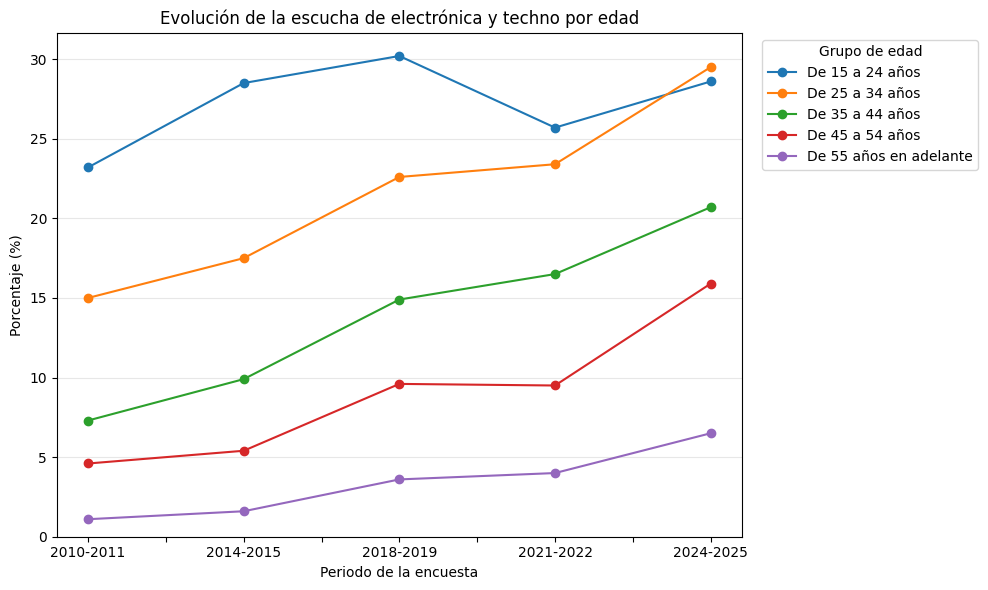

In [37]:
# Cada grupo de edad será una línea.
# .T intercambia filas y columnas para colocar los periodos en el eje horizontal.
ax = tabla_edades.T.plot(
    kind="line",
    marker="o",
    figsize=(10, 6)
)

# Añadimos título y nombres de los ejes.
ax.set_title("Evolución de la escucha de electrónica y techno por edad")
ax.set_xlabel("Periodo de la encuesta")
ax.set_ylabel("Porcentaje (%)")

# Comenzamos el eje vertical en cero para facilitar la comparación.
ax.set_ylim(bottom=0)

# Identificamos las líneas y añadimos una cuadrícula suave.
ax.legend(title="Grupo de edad", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", alpha=0.3)

# Ajustamos el espacio y mostramos el gráfico.
plt.tight_layout()
plt.show()

### Interpretación del gráfico: evolución por edad

Entre 2010–2011 y 2024–2025, el porcentaje de escucha de la categoría
«Electrónica, tecno» aumenta en todos los grupos de edad analizados.

El mayor aumento en puntos porcentuales corresponde al grupo de 25 a 34 años
(+14,5), seguido del de 35 a 44 años (+13,4).

En los grupos de mayor edad también se observa un aumento:
de 4,6 % a 15,9 % entre los 45 y 54 años (+11,3 puntos porcentuales)
y de 1,1 % a 6,5 % entre las personas de 55 años en adelante (+5,4 puntos).

La evolución no es uniforme: algunos grupos presentan descensos en 2021–2022
respecto a 2018–2019. Estos datos por sí solos no permiten explicar sus causas.

Los resultados muestran cambios en la escucha declarada de electrónica y techno.
No permiten concluir que haya aumentado la asistencia de estos grupos a fiestas,
ni seguir a las mismas personas a lo largo del tiempo.

,Porcentaje
Sexo y edad,
De 25 a 34 años,29.5
De 15 a 24 años,28.6
De 35 a 44 años,20.7
De 45 a 54 años,15.9
De 55 años en adelante,6.5


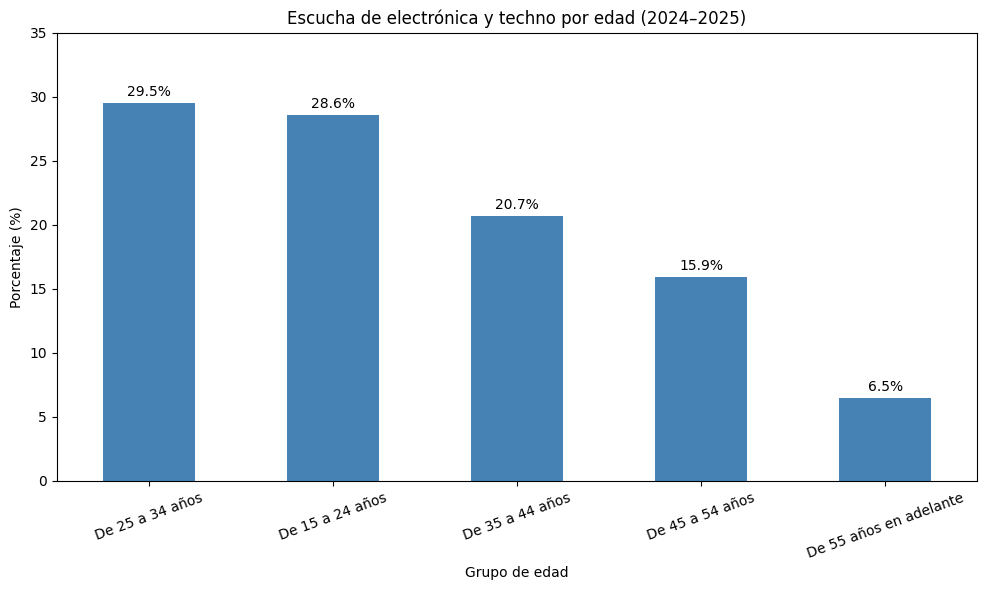

In [38]:
# Seleccionamos la columna del periodo más reciente.
# Ordenamos los porcentajes de mayor a menor.
edades_2024 = tabla_edades["2024-2025"].sort_values(ascending=False)

# Mostramos los valores que representaremos en el gráfico.
display(edades_2024.to_frame(name="Porcentaje"))

# Creamos un gráfico de barras para comparar los grupos de edad.
ax = edades_2024.plot(
    kind="bar",
    figsize=(10, 6),
    color="steelblue",
    rot=20
)

# Añadimos título y etiquetas.
ax.set_title("Escucha de electrónica y techno por edad (2024–2025)")
ax.set_xlabel("Grupo de edad")
ax.set_ylabel("Porcentaje (%)")
ax.set_ylim(0, 35)

# Escribimos el porcentaje encima de cada barra.
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)

# Ajustamos el espacio y mostramos el gráfico.
plt.tight_layout()
plt.show()

### Interpretación del gráfico: comparación por edad en 2024–2025

El grupo de 25 a 34 años presenta el mayor porcentaje de escucha de
«Electrónica, tecno» (29,5 %), seguido del grupo de 15 a 24 años (28,6 %).
La diferencia entre ambos es de 0,9 puntos porcentuales.

En los grupos de mayor edad, los porcentajes son del 15,9 % entre los
45 y 54 años y del 6,5 % entre las personas de 55 años en adelante.

Estos porcentajes describen la escucha dentro de cada colectivo.
No representan cómo se reparte por edades el conjunto de oyentes:
por ejemplo, el 15,9 % no significa que ese porcentaje de todos los
oyentes tenga entre 45 y 54 años.


In [39]:
# Seleccionamos solo Hombres y Mujeres.
# isin() comprueba si cada etiqueta está en la lista indicada.
techno_sexo = datos_techno.loc[
    datos_techno["Sexo y edad"].isin(["Hombres", "Mujeres"])
].copy()

# Organizamos la tabla: periodos en filas y sexo en columnas.
tabla_sexo = techno_sexo.pivot(
    index="periodo",
    columns="Sexo y edad",
    values="Porcentaje"
)

# Calculamos la diferencia en puntos porcentuales.
tabla_sexo["Diferencia (puntos porcentuales)"] = (
    tabla_sexo["Hombres"] - tabla_sexo["Mujeres"]
).round(1)

# Mostramos los porcentajes y la diferencia de cada periodo.
display(tabla_sexo)

Sexo y edad,Hombres,Mujeres,Diferencia (puntos porcentuales)
periodo,,,
2010-2011,12.1,6.2,5.9
2014-2015,13.8,6.9,6.9
2018-2019,17.4,9.5,7.9
2021-2022,15.8,10.1,5.7
2024-2025,21.8,12.2,9.6


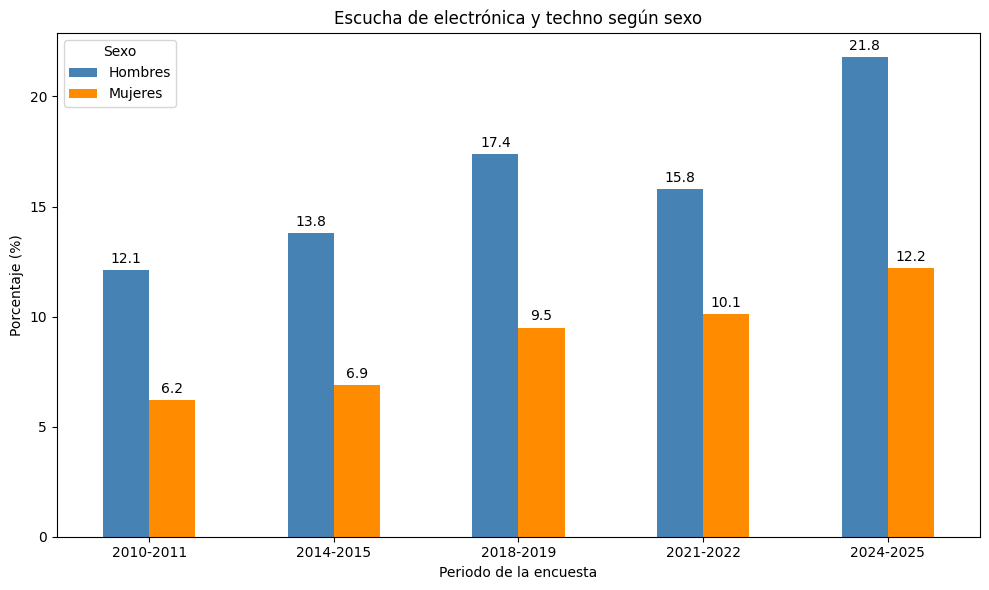

In [40]:
# Seleccionamos solo los porcentajes de Hombres y Mujeres.
# La diferencia calculada no se dibuja porque está en puntos porcentuales.
ax = tabla_sexo[["Hombres", "Mujeres"]].plot(
    kind="bar",
    figsize=(10, 6),
    color=["steelblue", "darkorange"],
    rot=0
)

# Añadimos título y nombres de los ejes.
ax.set_title("Escucha de electrónica y techno según sexo")
ax.set_xlabel("Periodo de la encuesta")
ax.set_ylabel("Porcentaje (%)")
ax.set_ylim(bottom=0)

# Mostramos el valor encima de cada barra.
for barras in ax.containers:
    ax.bar_label(barras, fmt="%.1f", padding=3)

# Colocamos la leyenda y ajustamos la presentación.
ax.legend(title="Sexo")
plt.tight_layout()
plt.show()

### Interpretación del gráfico: escucha según sexo

El porcentaje de escucha de «Electrónica, tecno» es mayor entre los hombres
que entre las mujeres en las cinco ediciones analizadas.

Entre 2010–2011 y 2024–2025, aumenta del 12,1 % al 21,8 % entre los hombres
y del 6,2 % al 12,2 % entre las mujeres.

La diferencia pasa de 5,9 puntos porcentuales en la primera edición
a 9,6 en la última. Sin embargo, no aumenta de forma continua:
en 2021–2022 es de 5,7 puntos.

Estos datos describen diferencias en la escucha declarada, pero no permiten
explicar sus causas. Tampoco indican que el 21,8 % del público sea masculino:
cada porcentaje se refiere a su propio colectivo.

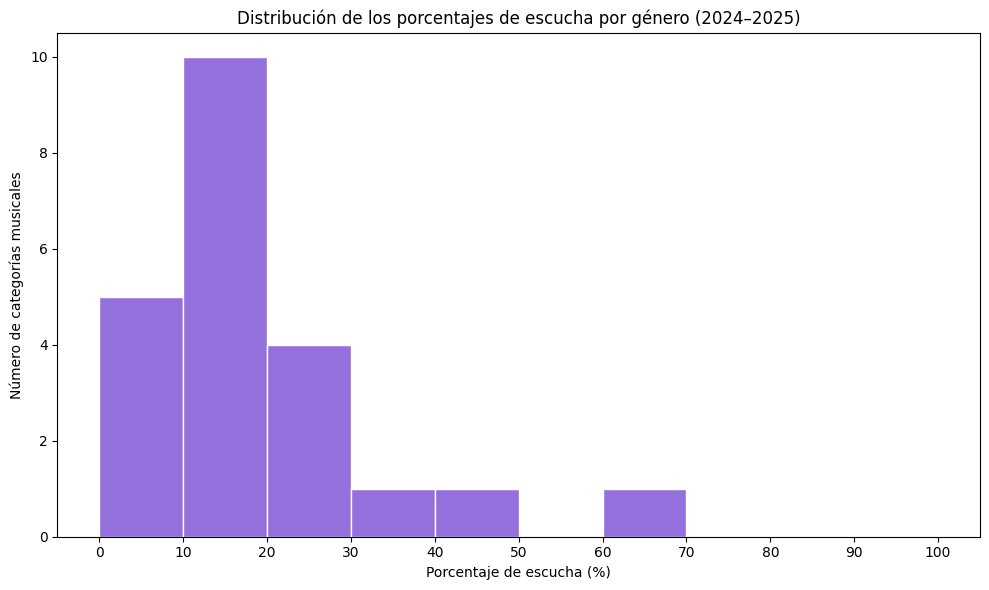

In [41]:
# Seleccionamos los porcentajes generales de cada género en 2024–2025.
generos_2024 = datos_porcentajes.loc[
    (datos_porcentajes["periodo"] == "2024-2025")
    & (datos_porcentajes["Sexo y edad"] == "TOTAL")
].copy()

# Creamos el histograma.
# Los intervalos van de 0 a 100 %, en tramos de 10 puntos.
fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(
    generos_2024["Total"],
    bins=range(0, 101, 10),
    color="mediumpurple",
    edgecolor="white"
)

# Añadimos título y nombres de los ejes.
ax.set_title("Distribución de los porcentajes de escucha por género (2024–2025)")
ax.set_xlabel("Porcentaje de escucha (%)")
ax.set_ylabel("Número de categorías musicales")
ax.set_xticks(range(0, 101, 10))

# El número de categorías se muestra con valores enteros.
from matplotlib.ticker import MaxNLocator
ax.yaxis.set_major_locator(MaxNLocator(integer=True))

plt.tight_layout()
plt.show()

### Interpretación del histograma

El histograma muestra cómo se distribuyen los porcentajes de escucha
de las categorías musicales en 2024–2025.

El eje horizontal agrupa los porcentajes en intervalos de 10 puntos.
La altura de cada barra indica cuántas categorías musicales están
en ese intervalo; no representa una cantidad de personas.

La categoría «Electrónica, tecno», con un 17 %, se encuentra
en el intervalo de 10 a menos de 20 %.

In [42]:
# Seleccionamos el nombre del género y su porcentaje.
# Ordenamos de mayor a menor porcentaje de escucha.
display(
    generos_2024[["Género musical", "Total"]]
    .sort_values("Total", ascending=False)
    .rename(columns={"Total": "Porcentaje"})
    .reset_index(drop=True)
)

,Género musical,Porcentaje
0,"Pop, Rock español",60.3
1,"Pop, Rock extranjero",43.4
2,"Pop, Rock latino",31.7
3,Canción de autor,26.3
4,Canción melódica,24.1
5,Flamenco,21.2
6,"Trap, Reggaetón",20.1
7,Música clásica,19.5
8,"Electrónica, tecno",17.0
9,Otros,16.5


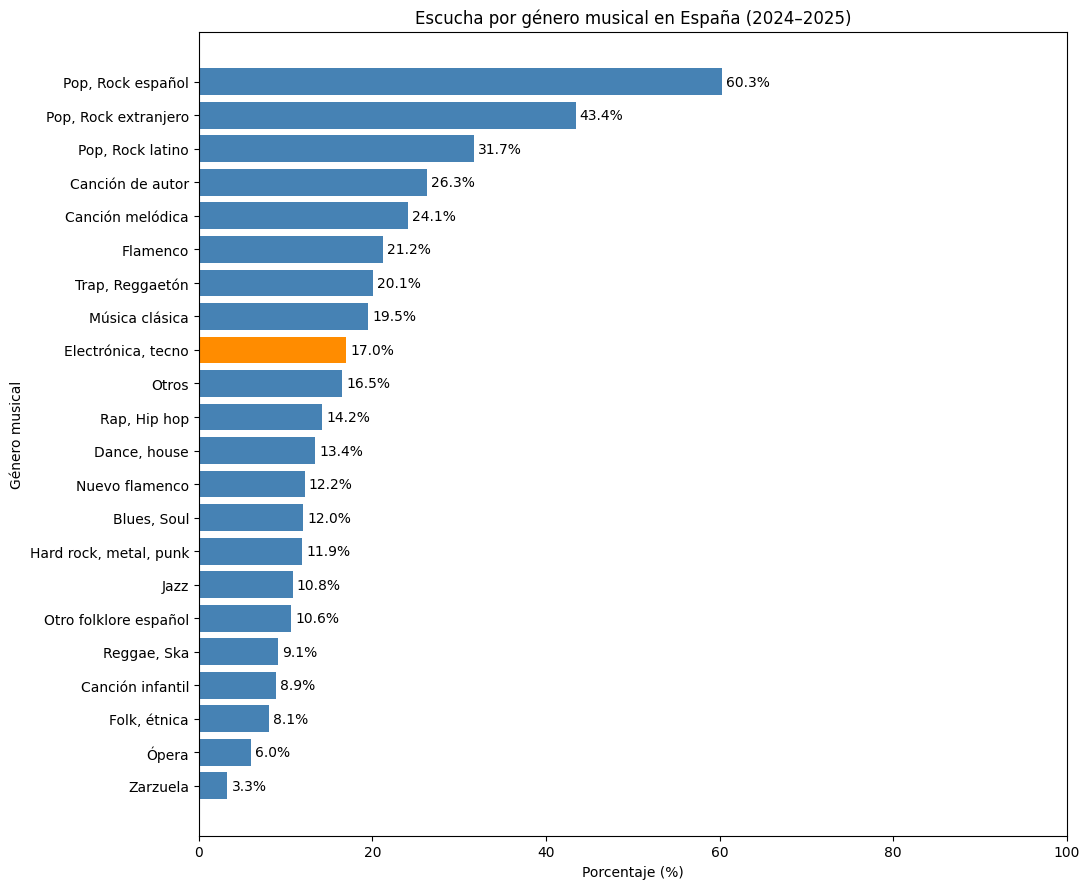

In [43]:
# Ordenamos los géneros de menor a mayor para que,
# al dibujar barras horizontales, el mayor quede arriba.
generos_ordenados = generos_2024.sort_values("Total")

# Destacamos electrónica y techno en naranja.
# Los demás géneros aparecerán en azul.
colores = [
    "darkorange" if genero == "Electrónica, tecno" else "steelblue"
    for genero in generos_ordenados["Género musical"]
]

# Creamos el gráfico de barras horizontales.
fig, ax = plt.subplots(figsize=(11, 9))

barras = ax.barh(
    generos_ordenados["Género musical"],
    generos_ordenados["Total"],
    color=colores
)

# Mostramos el porcentaje al final de cada barra.
ax.bar_label(barras, fmt="%.1f%%", padding=3)

# Añadimos título, etiquetas y espacio para los valores.
ax.set_title("Escucha por género musical en España (2024–2025)")
ax.set_xlabel("Porcentaje (%)")
ax.set_ylabel("Género musical")
ax.set_xlim(0, 100)

plt.tight_layout()
plt.show()

### Interpretación de las barras horizontales

Este gráfico permite identificar cada categoría musical y comparar
sus porcentajes de escucha. La categoría «Electrónica, tecno»
se destaca en naranja para situarla frente a los demás géneros.

Como la pregunta admite respuestas múltiples, una misma persona
puede escuchar varios géneros. Por eso, estos porcentajes
no son partes de un total que deba sumar 100 %.
### Resultados de la comparación entre géneros

En 2024–2025, las categorías con mayor porcentaje de escucha son
«Pop, Rock español» (60,3 %), «Pop, Rock extranjero» (43,4 %)
y «Pop, Rock latino» (31,7 %).

«Electrónica, tecno» alcanza el 17 % y ocupa la novena posición
entre las 22 categorías incluidas. Se sitúa por debajo de
«Música clásica» (19,5 %) y por encima de «Rap, Hip hop» (14,2 %).

El intervalo de 10 a menos de 20 % concentra más categorías:
10 de las 22. Esto explica por qué esa barra es la más alta
del histograma.

Los porcentajes no deben sumarse, porque una misma persona
puede haber seleccionado varios géneros.

In [44]:
# Resumimos los porcentajes de los cinco grupos de edad por periodo.
# describe() calcula cantidad, media, desviación, mínimo,
# cuartiles y máximo.
display(tabla_edades.describe().round(2))

periodo,2010-2011,2014-2015,2018-2019,2021-2022,2024-2025
count,5.00,5.00,5.00,5.00,5.00
mean,10.24,12.58,16.18,15.82,20.24
std,8.87,10.69,10.50,9.15,9.53
min,1.10,1.60,3.60,4.00,6.50
25%,4.60,5.40,9.60,9.50,15.90
50%,7.30,9.90,14.90,16.50,20.70
75%,15.00,17.50,22.60,23.40,28.60
max,23.20,28.50,30.20,25.70,29.50


### Cómo interpretar el resumen estadístico

Cada columna corresponde a un periodo y resume los porcentajes
de los cinco grupos de edad.

- count: número de grupos analizados (5).
- mean: promedio simple de sus porcentajes.
- std: dispersión de los porcentajes entre los grupos.
- min y max: menor y mayor porcentaje.
- 25%, 50% y 75%: cuartiles; el 50% corresponde a la mediana.

La media no representa el porcentaje general de escucha:
cada grupo tiene el mismo peso en este cálculo, aunque sus
poblaciones sean de distinto tamaño.

## Conclusiones

### Principales descubrimientos

1. Entre 2010–2011 y 2024–2025, la escucha declarada de «Electrónica, tecno»
aumenta en todos los grupos de edad analizados. El mayor incremento
corresponde al grupo de 25 a 34 años: 14,5 puntos porcentuales.

2. También aumenta en los grupos de mayor edad. Entre los 45 y 54 años
pasa del 4,6 % al 15,9 %, y entre las personas de 55 años en adelante,
del 1,1 % al 6,5 %. La escucha de esta categoría se extiende más allá
de los grupos jóvenes.

3. El porcentaje de escucha es mayor entre los hombres que entre las mujeres
en las cinco ediciones. En 2024–2025 alcanza el 21,8 % y el 12,2 %,
respectivamente: una diferencia de 9,6 puntos porcentuales.

### Relación con la motivación inicial

Mi observación sobre la presencia de personas mayores de 40 años en fiestas
motivó este análisis. Los resultados muestran un aumento de la escucha
en los grupos de mayor edad, pero no permiten confirmar un aumento
de su asistencia a fiestas.

### Posible aplicación

Estos resultados justifican investigar las preferencias de distintos
grupos de edad antes de diseñar una propuesta musical o un evento.
La escucha, por sí sola, no permite estimar la demanda de entradas.

### Datos adicionales necesarios

Para estudiar mi pregunta inicial necesitaría datos de asistencia
a eventos de techno por edad y año, con información sobre el total
de asistentes y un método de recogida comparable.

### Limitaciones

La encuesta agrupa electrónica y techno en una misma categoría.
Los intervalos de edad no permiten aislar exactamente a los mayores de 40.
Además, las distintas ediciones no siguen necesariamente a las mismas personas.
Las diferencias observadas son descriptivas: no hemos evaluado
su significación estadística ni establecido sus causas.